# Expoure maps
This Notebook produces horizontal plots for selected time slices of: 
* horizontal expoure maps 
* climate index absolute
* climate index change
* population absolute
* population change
* person events absolute
* person events change (exposure)

The exposure is calculated using the formula:

$\Delta E = P_r \times \Delta C + C_r \times \Delta P + \Delta C \times \Delta P$

Weber (2019) https://doi.org/10.1029/2019EF001473

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import os
import glob

import xarray as xr

In [3]:
from plotting_tools_africa import directory_available, plot_diff, plot_absolut
from plotting_tools_exposure import plot_absolute_pop, plot_diff_pop, plot_diff_exposure
from format_data_tools import save_file_to_netcdf
from colors_indices import colorsteps_diff, colorsteps_absolute, colorsteps_exposure
from exposure import diff_exposure, exposure

In [4]:
# Directories need to be defined
database='/work/ch0636/g300047/cicles/'
pop_dir = os.path.join(database, 'population')
data_dir=os.path.join(database, 'climate_fact_data/hori_results_afr22/')
plot_dir = os.path.join(database,'factsheet_africa/PLOTS/horizontal-plots-exposure/')

In [5]:
#landsea mask
lsm=os.path.join(database,'data_factsheet_github'+'/land_sea_mask_afr22.nc')

In [6]:
directory_available(plot_dir)

In [7]:
def sel_time_mean(ds, start, end):
    return ds.sel(time=slice(start, end)).mean(dim="time")

The population data got remapped to arf22 grid in a 
separate script **remap_population_to_afr22.ipynb**. All references and source are stored in that notebook.

**Only needs to be done once**
The following funktion contains a lot of specific year, 
Please have a look and adjust to your needs

### Get List of population files

In [8]:
# get list of population diff and absolute files
pop_ssp1 = [
    pop_dir+ '/pop_1991_2020_ssp1.nc',
    pop_dir+ '/pop_2031_2060_ssp1.nc',
    pop_dir+ '/pop_2069_2098_ssp1.nc']
pop_ssp3 = [
    pop_dir+ '/pop_1991_2020_ssp3.nc',
    pop_dir+ '/pop_2031_2060_ssp3.nc',
    pop_dir+ '/pop_2069_2098_ssp3.nc']
pop_diff_ssp1 = [
    pop_dir+ '/pop_diff_2031_2060_ssp1.nc',
    pop_dir+ '/pop_diff_2069_2098_ssp1.nc']
pop_diff_ssp3 = [
    pop_dir+ '/pop_diff_2031_2060_ssp3.nc',
    pop_dir+ '/pop_diff_2069_2098_ssp3.nc']
pop_diff_ssp1


['/work/ch0636/g300047/cicles/population/pop_diff_2031_2060_ssp1.nc',
 '/work/ch0636/g300047/cicles/population/pop_diff_2069_2098_ssp1.nc']

#### climate data 
* SU40
* Tropical nights (TR)
* R20mm
* dry days (DD)

In [9]:
# Detemine the variable 
# Time resolution you like
#var='SU30'
#var='SU35'
var='SU40'
#var='TR'
#var='TR26'
#var='R20mm'
#var='DD'

robust='_ensemble-robustness.nc'
list_rcp26 = "rcp26"
list_rcp85 = "rcp85"
title_part="Ensemble Median of the change compared to 1991-2020: \n "

# Chose if you like median or mean of the differences
what='_time-mean_ensemble-diff-median.nc'
# Chose if you like median or mean of the absolute values
which_ensemble='_time-mean_ensemble-median.nc'

#### Check if title_part is consitent with file you are reading, you can chose between median and mean

In [10]:
# Get the list of files for difference plots
timefreq='year_2'
sims_rcp26_diff = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp26+'*'+what)
sims_rcp85_diff = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp85+'*'+what)
robust_rcp26 = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp26+'*'+robust)
robust_rcp85 = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp85+'*'+robust)
# Sort the files to ensure correct order
sims_rcp26_diff.sort()
sims_rcp85_diff.sort()
robust_rcp26.sort()
robust_rcp85.sort()

In [11]:
# Have a look which files are being processed:
sims_rcp85_diff

['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2031_2060_rcp85_time-mean_ensemble-diff-median.nc',
 '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2069_2098_rcp85_time-mean_ensemble-diff-median.nc']

#### Get list of file for absolute plots

In [12]:
# Get the list of files for absolute plots
timefreq='year'

sims_rcp26 = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp26+'*'+which_ensemble)
sims_rcp85 = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp85+'*'+which_ensemble)
# Sort the files to ensure correct order
sims_rcp26.sort()
sims_rcp85.sort()

In [13]:
# check
sims_rcp85

['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_1991_2020_rcp85_time-mean_ensemble-median.nc',
 '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2031_2060_rcp85_time-mean_ensemble-median.nc',
 '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2069_2098_rcp85_time-mean_ensemble-median.nc']

In [14]:
df_tmp = xr.open_dataset(sims_rcp26[0])
long_name = df_tmp[var].attrs.get('long_name', 'long_name attribute missing')
print(long_name)

/tmp/ipykernel_785561/1770114163.py:1: FutureWarning: In a future version, xarray will not decode the variable 'SU40' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  df_tmp = xr.open_dataset(sims_rcp26[0])


Number of summer days (maximum temperature > 40.0 degC)


### For the plots you have to make some decisions in the next box:
* Do you like to plot West Africa (True) or Africa (False)
* user_dpi is the resolution of the saved figure, for printing 1200 is recommended, otherwise use 300, which is faster
* title: add a title to the plot according to your file selection (median, mean, etc)

Selected colors, levels for plotting  SU40
['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_1991_2020_rcp26_time-mean_ensemble-median.nc', '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2031_2060_rcp26_time-mean_ensemble-median.nc', '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2069_2098_rcp26_time-mean_ensemble-median.nc']
['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_1991_2020_rcp85_time-mean_ensemble-median.nc', '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2031_2060_rcp85_time-mean_ensemble-median.nc', '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2069_2098_rcp85_time-mean_ensemble-median.nc']
sims_rcp26 ['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_1991_2020_rcp26_time-mean_ensemble-median.nc', '/work/ch0636/g300047/cicles/climate_fac

/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_africa.py:557: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0.03, 0.08, 0.97, 0.93])


file is here: /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//SU40_absolut_West_Africa_1200.png
plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//SU40_absolut_West_Africa_1200.png


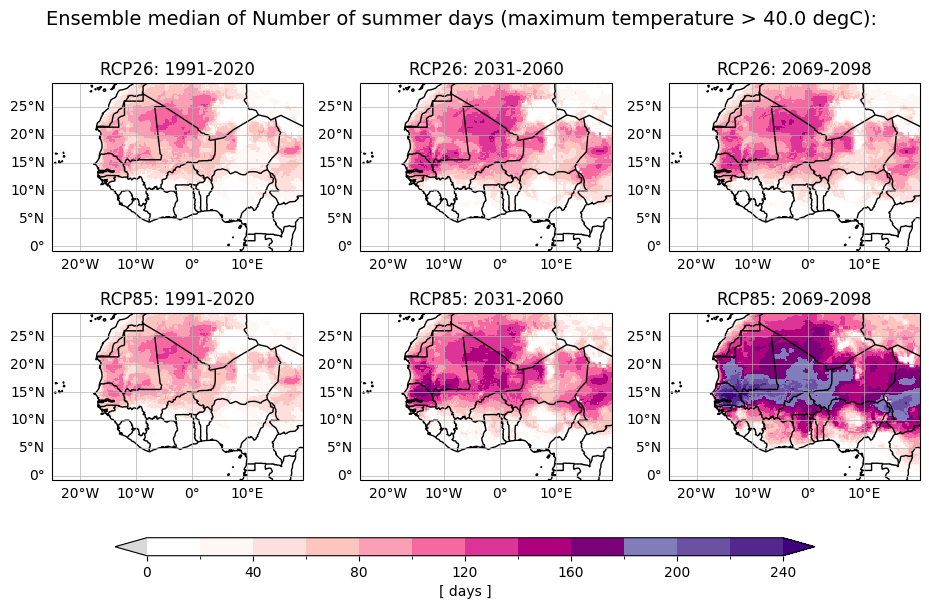

In [15]:
print('Selected colors, levels for plotting ', var)
color_steps, level_steps = colorsteps_absolute(var)

# Now plot the absolute values
plot_absolut(
    sims_rcp26,
    sims_rcp85,
    level_steps, 
    color_steps,    
    plot_dir,
    title="Ensemble median of",
    var=var,
    westafrica=True,
    user_dpi=1200,
    rows=2, 
    columns=3,
    )

#### plot absolute population

%pip uninstall -q h5netcdf scipy

['/work/ch0636/g300047/cicles/population/pop_1991_2020_ssp1.nc', '/work/ch0636/g300047/cicles/population/pop_2031_2060_ssp1.nc', '/work/ch0636/g300047/cicles/population/pop_2069_2098_ssp1.nc']
['/work/ch0636/g300047/cicles/population/pop_1991_2020_ssp3.nc', '/work/ch0636/g300047/cicles/population/pop_2031_2060_ssp3.nc', '/work/ch0636/g300047/cicles/population/pop_2069_2098_ssp3.nc']
/work/ch0636/g300047/cicles/population/pop_1991_2020_ssp1.nc
/work/ch0636/g300047/cicles/data_factsheet_github/land_sea_mask_afr22.nc
/work/ch0636/g300047/cicles/population/pop_2031_2060_ssp1.nc
/work/ch0636/g300047/cicles/data_factsheet_github/land_sea_mask_afr22.nc
/work/ch0636/g300047/cicles/population/pop_2069_2098_ssp1.nc
/work/ch0636/g300047/cicles/data_factsheet_github/land_sea_mask_afr22.nc
plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//number_of_people_absolut_West_Africa_1200.png


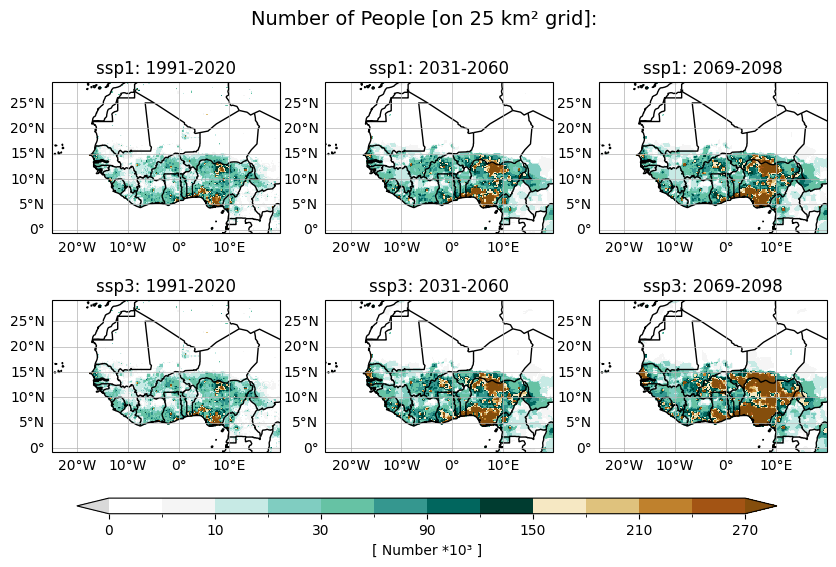

In [16]:
pop_color_steps, pop_level_steps = colorsteps_absolute('number_of_people')
plot_absolute_pop(
    pop_ssp1,
    pop_ssp3,
    pop_level_steps, 
    pop_color_steps,    
    plot_dir,
    title="on 25 km² grid",
    varp='number_of_people',
    lsm=lsm,
    westafrica=True,
    user_dpi=1200,
    rows=2, 
    columns=3,
    )

#### plot population change

file:  /work/ch0636/g300047/cicles/population/pop_diff_2031_2060_ssp1.nc
file:  /work/ch0636/g300047/cicles/population/pop_diff_2069_2098_ssp1.nc
plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//number_of_people_diff_West_Africa_1200.png


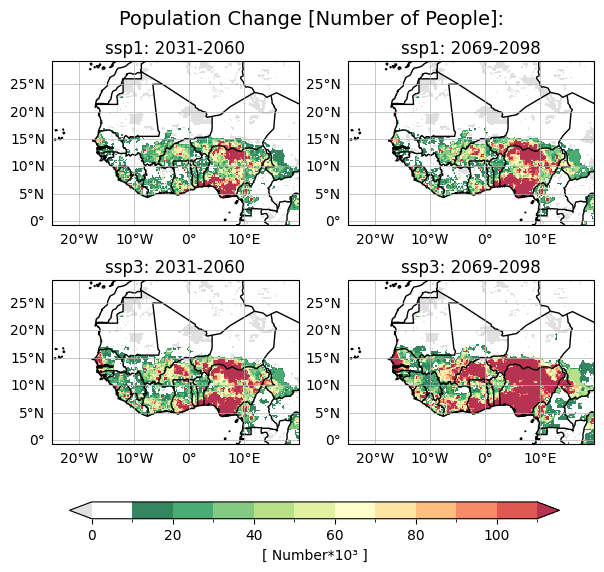

In [17]:
color_steps_diff, level_steps_diff = colorsteps_diff('number_of_people')

#Plot 2 diff for population
plot_diff_pop(
     pop_diff_ssp1,
     pop_diff_ssp3,
     level_steps_diff, 
     color_steps_diff, 
     plot_dir,
     title='Population Change',
     varp='number_of_people',
     #westafrica=False, 
     westafrica=True,
     user_dpi=1200,
     rows=2, 
     columns=2,
     row_gap=0.35,
     wspace=None
    )


#### plot climate change

Selected colors, levels for plotting  SU40
/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2031_2060_rcp26_time-mean_ensemble-diff-median.nc
nothing to do, unit exists
/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2069_2098_rcp26_time-mean_ensemble-diff-median.nc
nothing to do, unit exists
plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//SU40_diff-robust_West_Africa_300.png


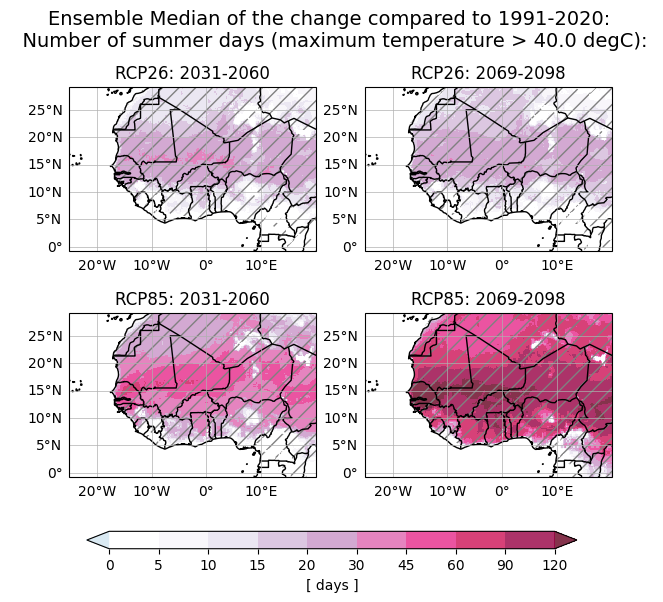

In [20]:
# get colors and levels for plotting
print('Selected colors, levels for plotting ', var)

color_steps_diff, level_steps_diff = colorsteps_diff(var)

plot_diff(
     sims_rcp26_diff,
     sims_rcp85_diff,
     level_steps_diff,
     color_steps_diff,
     what,
     robust,
     plot_dir,
     title=title_part,
     var=var,
     robustness=True,
     #westafrica=False, 
     westafrica=True,
     user_dpi=300,
     rows=2, 
     columns=2,
     row_gap=-0.05,
     wspace=None
    )

In [21]:
def get_time_slice(n: int) -> str:
    """
    Return the time slice string for index n.
    n=0 -> '2031_2060'
    n=1 -> '2069_2098'
    """
    if n == 0:
        return '2031_2060'
    if n == 1:
        return '2069_2098'
    raise ValueError(f"Unsupported index {n}; expected 0 or 1.")


In [22]:
def get_time_slice_absolute(n: int) -> str:
    """
    Return the time slice string for index n.
    n=0 -> '1991_2020'
    n=1 -> '2031_2060'
    n=2 -> '2069_2098'
    """
    if n == 0:
        return '1991_2020'
    if n == 1:
        return '2031_2060'
    if n == 2:
        return '2069_2098'
    raise ValueError(f"Unsupported index {n}; expected 0, 1, or 2.")


### calculate person events

In [23]:
# Calculated person events by multplying population with climate index
# calculate for 1991-2024 and 2031-2060
# For Bulletin, we use the 2031-2060 time period.
# Get the list of files for absolute plots
exposure_ssp1 = []
exposure_ssp3 = []
exposure_files_ssp1 = []
exposure_files_ssp3 = []

for n in range(0, 3):
    person_event_ssp1 = exposure(pop_ssp1[n], sims_rcp26[n], var)
    person_event_ssp3 = exposure(pop_ssp3[n], sims_rcp85[n], var)
    time_slice = get_time_slice_absolute(n)
    save_file_to_netcdf(person_event_ssp1, pop_dir, f'/{var}_year_{time_slice}_ssp1_person_event.nc' )
    save_file_to_netcdf(person_event_ssp3, pop_dir, f'/{var}_year_{time_slice}_ssp3_person_event.nc')

    exposure_ssp1.append(person_event_ssp1)
    exposure_ssp3.append(person_event_ssp3)

    exposure_files_ssp1.append(pop_dir+ f'/{var}_year_{time_slice}_ssp1_person_event.nc')
    exposure_files_ssp3.append(pop_dir+ f'/{var}_year_{time_slice}_ssp3_person_event.nc')

['/work/ch0636/g300047/cicles/population/SU40_year_1991_2020_ssp1_person_event.nc', '/work/ch0636/g300047/cicles/population/SU40_year_2031_2060_ssp1_person_event.nc', '/work/ch0636/g300047/cicles/population/SU40_year_2069_2098_ssp1_person_event.nc']
['/work/ch0636/g300047/cicles/population/SU40_year_1991_2020_ssp3_person_event.nc', '/work/ch0636/g300047/cicles/population/SU40_year_2031_2060_ssp3_person_event.nc', '/work/ch0636/g300047/cicles/population/SU40_year_2069_2098_ssp3_person_event.nc']
/work/ch0636/g300047/cicles/population/SU40_year_1991_2020_ssp1_person_event.nc
/work/ch0636/g300047/cicles/data_factsheet_github/land_sea_mask_afr22.nc
person_events
/work/ch0636/g300047/cicles/population/SU40_year_2031_2060_ssp1_person_event.nc
/work/ch0636/g300047/cicles/data_factsheet_github/land_sea_mask_afr22.nc
person_events
/work/ch0636/g300047/cicles/population/SU40_year_2069_2098_ssp1_person_event.nc
/work/ch0636/g300047/cicles/data_factsheet_github/land_sea_mask_afr22.nc
person_events

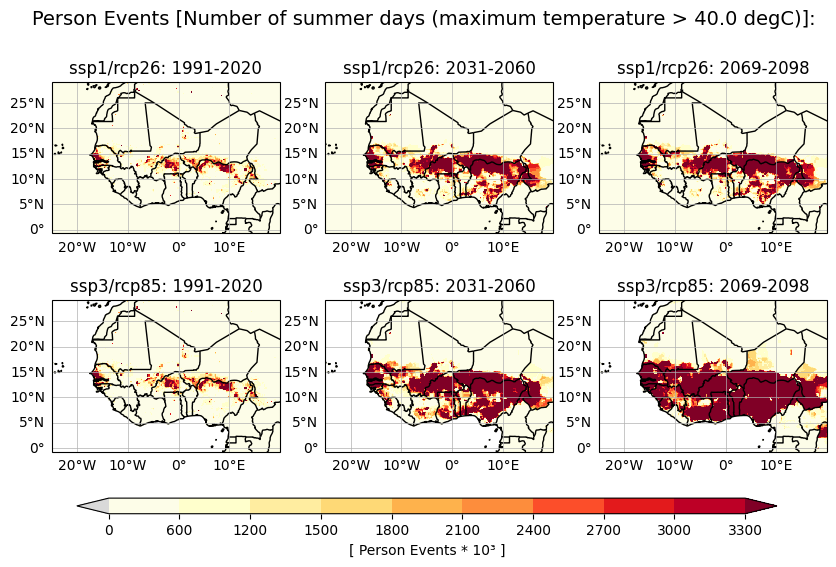

In [24]:
# Now plot absolute person events
color_steps_exp, level_steps_exp = colorsteps_exposure('person_events')
    
plot_absolute_pop(
    exposure_files_ssp1,
    exposure_files_ssp3,
    level_steps_exp, 
    color_steps_exp,    
    plot_dir,
    title=long_name,
    varp='person_events',
    lsm=lsm,
    westafrica=True,
    user_dpi=1200,
    rows=2, 
    columns=3,
    )

### calculate exposure change

In [25]:
# Here for Factsheet:
exposure_change_ssp1 = []
exposure_change_ssp3 = []
exposure_change_files_ssp1 = []
exposure_change_files_ssp3 = []
for n in range(0, 2):
    change_ssp1 = diff_exposure(pop_ssp1[0], sims_rcp26[0], pop_diff_ssp1[n], sims_rcp26_diff[n], var)
    change_ssp3 = diff_exposure(pop_ssp3[0], sims_rcp85[0], pop_diff_ssp3[n], sims_rcp85_diff[n], var)
    
    time_slice = get_time_slice(n)
    save_file_to_netcdf(change_ssp1, pop_dir, f'/{var}_year_{time_slice}_ssp1_exposure_change.nc')
    save_file_to_netcdf(change_ssp3, pop_dir, f'/{var}_year_{time_slice}_ssp3_exposure_change.nc')
    
    exposure_change_ssp1.append(change_ssp1)
    exposure_change_ssp3.append(change_ssp3)
    exposure_change_files_ssp1.append(pop_dir+ f'/{var}_year_{time_slice}_ssp1_exposure_change.nc')
    exposure_change_files_ssp3.append(pop_dir+ f'/{var}_year_{time_slice}_ssp3_exposure_change.nc')

Selected colors, levels for plotting  SU40
/work/ch0636/g300047/cicles/population/SU40_year_2031_2060_ssp1_exposure_change.nc
True
robust file:  /work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2031_2060_rcp26_ensemble-robustness.nc
/work/ch0636/g300047/cicles/population/SU40_year_2069_2098_ssp1_exposure_change.nc
True
robust file:  /work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2069_2098_rcp26_ensemble-robustness.nc
plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//exposure_SU40_diff-robust_West_Africa_1200.png


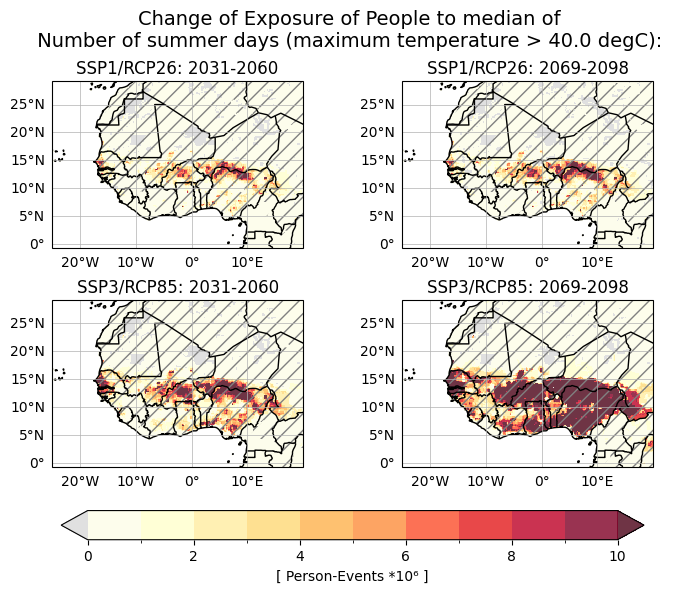

In [26]:
print('Selected colors, levels for plotting ', var)

color_steps_exp, level_steps_exp = colorsteps_exposure('exposure')

plot_diff_exposure(
     exposure_change_files_ssp1,
     exposure_change_files_ssp3,
     robust_rcp26,
     robust_rcp85,
     plot_dir,
     level_steps_exp, 
     color_steps_exp,
     title=f'Change of Exposure of People to median of\n {long_name}',
     var='exposure',
     varr=var,
     lsm=lsm,
     robustness=True,
     westafrica=True,
     user_dpi=1200,
     rows=2, 
     columns=2,
    )
